# Does AFL scoring drop after the first six rounds of the home-and-away season?

*Milestone 1 of a Python learning project: reproducing an analysis I originally wrote in R.*

**Question.** Does AFL scoring drop after the first six rounds of the home-and-away season, and how consistently has that held from 2016 to 2025.

**Data.** Home-and-away match results for 2016 to 2025 from [AFL Tables](https://afltables.com), pulled with the [fitzRoy](https://github.com/jimmyday12/fitzRoy) R package and saved as `afl_match_data.csv` (one row per match). Finals are excluded; Opening Round matches are coded as Round 0.

**Original R analysis.**
  1. Early (Rounds 0 to 6) vs rest-of-season average points per team for every season, with the drop and how many seasons show early scoring higher.
  2. The full early vs rest summary for 2025: games, average team score, average combined score, average winning margin, % of games with a 100+ score, and highest combined score.

**Chart:** Paired bars by season comparing early-season and rest-of-season average points per team.

**Result.** Write this last: the headline finding, and whether Python matched R.

## Setup

In [96]:
from pathlib import Path

import pandas as pd
import numpy as np

DATA = Path("data")          # raw data used by both versions
R_OUT = Path("r_outputs")    # CSVs exported from your R script, for the parity checks

## Parity helper

Export each R result you want to match from R as a CSV, for example:

```r
write.csv(summary_1, "r_outputs/summary_1.csv", row.names = FALSE)
```

Then compare it with the Python result. The helper ignores small floating-point differences and integer versus float types, and prints exactly where any real difference is.

In [97]:
def compare_to_r(py_df, r_csv, sort_by=None, rtol=1e-6):
    """Compare a pandas DataFrame with a CSV exported from R. Prints MATCH or the first difference."""
    r_df = pd.read_csv(r_csv)
    left, right = py_df.reset_index(drop=True), r_df
    if sort_by:
        left = left.sort_values(sort_by).reset_index(drop=True)
        right = right.sort_values(sort_by).reset_index(drop=True)
    try:
        pd.testing.assert_frame_equal(left, right, check_dtype=False, check_exact=False, rtol=rtol)
        print(f"MATCH    {r_csv}")
    except AssertionError as e:
        print(f"DIFFERS  {r_csv}\n{e}")

## 1. Load the data

In [98]:
df = pd.read_csv("data/afl_match_data.csv")
df.head()

,season,round,round_name,home_team,home_nickname,away_team,away_nickname,home_score,away_score,venue,combined_score,avg_team_score,margin,winning_team,home_100_plus,away_100_plus,season_phase
0,2016,1,R1,Richmond,Tigers,Carlton,Blues,92,83,M.C.G.,175,87.5,9,Richmond,False,False,Early (Rds 0-6)
1,2016,1,R1,Melbourne,Demons,GWS,Giants,80,78,M.C.G.,158,79.0,2,Melbourne,False,False,Early (Rds 0-6)
2,2016,1,R1,Gold Coast,Suns,Essendon,Bombers,121,60,Carrara,181,90.5,61,Gold Coast,True,False,Early (Rds 0-6)
3,2016,1,R1,North Melbourne,Kangaroos,Adelaide,Crows,107,97,Docklands,204,102.0,10,North Melbourne,True,False,Early (Rds 0-6)
4,2016,1,R1,Sydney,Swans,Collingwood,Magpies,133,53,S.C.G.,186,93.0,80,Sydney,True,False,Early (Rds 0-6)


## 2. Reproduce result 1

**Result 1:** early vs rest of season, by season (mirrors rows 10-17 of *export_results.R*)

In [99]:
df_1 = df[df["season"] <= 2025]  # filter out future seasons

df_1 = df_1.assign(phase = lambda d: np.where(d["round"] <= 6, "early", "rest"))

summary_1 = df_1.groupby(["season", "phase"], as_index = False).agg(
    avg_team_score = ("avg_team_score", "mean")
)

wide = summary_1.pivot_table(
        index   = "season",
        columns = "phase",
        values  = "avg_team_score"
    ).reset_index()

wide.columns = [
    "season" if col == "season" else f"avg_{col}"
    for col in wide.columns
]

wide = wide.assign(
    drop = lambda d: d["avg_rest"] - d["avg_early"],
    early_higher = lambda d: d["avg_early"] > d["avg_rest"]
)

wide.head(11)

compare_to_r(wide, "r_outputs/season_gap.csv")

MATCH    r_outputs/season_gap.csv


## 3. Reproduce result 2

**Result 2:** early vs rest summary for 2025 (mirrors rows 19-33 of *export_results.R*)

In [100]:
df_2 = df[df["season"] == 2025]  # filter out future seasons

df_2 = df_2.assign(phase = lambda d: np.where(d["round"] <= 6, "Early (Rds 0-6)", "Rest of Season"))


summary_2 = df_2.groupby("phase", as_index = False).agg(
    games               = ("phase", "count"),
    avg_team_score      = ("avg_team_score", "mean"),
    avg_combined        = ("combined_score", "mean"),
    avg_margin          = ("margin", "mean"),
    pct_100_plus        = ("phase", lambda d: 
                    np.mean((df.loc[d.index, "home_score"] >= 100) | (df.loc[d.index, "away_score"] >= 100)) * 100),
    highest_combined    = ("combined_score", "max")
)

summary_2.head()

compare_to_r(summary_2, "r_outputs/phase_summary_2025.csv")

MATCH    r_outputs/phase_summary_2025.csv


## 4. One chart

`df.plot()` is enough for this milestone (run `uv add matplotlib` once first). plotnine, the ggplot2 equivalent, arrives in Session 11.

/var/folders/_3/26pxm6vj78v4wdc28vwgvp2c0000gn/T/ipykernel_28548/2398620565.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  ax.figure.show()


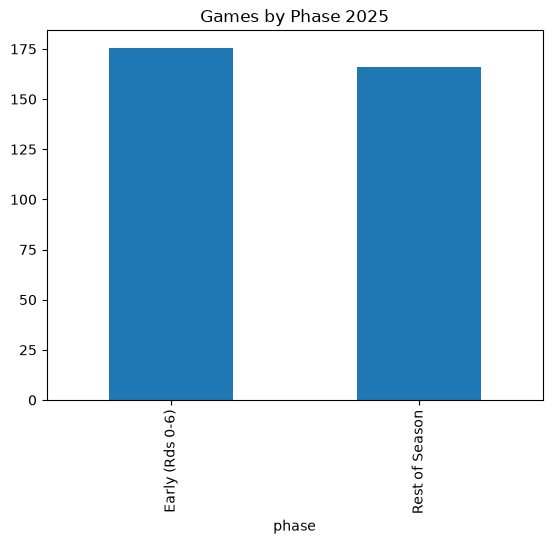

In [101]:
import matplotlib.pyplot as plt

ax = summary_2.plot(x="phase", y="avg_combined", kind="bar", title="Games by Phase 2025", legend=False)

# print the chart
ax.figure.show()

ax.figure.savefig("chart_1.png", dpi=150, bbox_inches="tight")

## 5. Findings

- **Finding 1:** In all but one season since 2016, the average score by teams in the first 6 rounds were higher than that of the rest of the season
- **Finding 2:** In season 2025, all of the measures (*avg_team_score, avg_combined, avg_margin, pct_100_plus, highest_combined*) were higher in the first 6 rounds of the season compared to the rest of the season.


## 6. Where R and Python differed

R looks a lot more intuitive when writing and mutating datasets.  Doing multiple steps of data manipulation in one bit of code is a lot clearer in R, Python is a bit messy.  Pandas and Numpy make it a little easier to read and learn quicker.  I am still getting used to if else logic.

What needed care to make the outputs match: attemtion to detail on the measures, the data for this exercise was very clean and didnt need much treatement